# Jacobian of the matter power spectrum

How the matter power spectrum $P(k, a)$ responds to every parameter, in scale and time. `jax.jacfwd` of one function gives the Jacobian with respect to ten parameters of $w_0 w_a$CDM with a massive neutrino.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import W0WACDM_MNU, background_history, solve_eb

K = np.geomspace(1.0e-4, 1.0, 64)  # wave numbers, 1/Mpc
A_OUT = np.geomspace(0.01, 1.0, 48)  # scale factors of the map

## The model and its parameters

`W0WACDM_MNU` has a dark-energy fluid with $w(a) = w_0 + w_a (1 - a)$ and one massive neutrino. `PARAMETERS` names the ten keys to differentiate and their labels.

In [2]:
fiducial = W0WACDM_MNU(
    Omegam=0.3099,
    Omegab=0.0488911,
    H0=67.742,
    A_s=2.1064e-9,
    n_s=0.96822,
    Tcmb=2.7255,
    YHe=0.248,
    Neff=2.046,  # the massless flavours
    Nmnu=1,
    mnu=0.06,  # eV
    w_DE_0=-0.99,
    w_DE_a=0.0,
    cs2_DE=1.0,
)
PARAMETERS = {  # key: label
    "H0": "H_0",
    "Omegam": r"\Omega_m",
    "Omegab": r"\Omega_b",
    "Neff": r"N_\mathrm{eff}",
    "mnu": r"m_\nu",
    "Tcmb": r"T_\mathrm{CMB}",
    "A_s": "A_s",
    "n_s": "n_s",
    "w_DE_0": "w_0",
    "w_DE_a": "w_a",
}
theta = jnp.asarray([getattr(fiducial, key) for key in PARAMETERS])

## Save times

`solve_eb` records at conformal times, and a derivative of its values holds those times fixed. A result at a fixed redshift needs the scale factor kept beside the other quantities at a few save times around it. An interpolation in `a` then gives every quantity at exactly that redshift, and JAX carries the shift of $a(\tau)$ with the parameters.

`background_history` gives the fiducial $a(\tau)$ on the host, enough to place the save times from before the first wanted scale factor until today.

In [3]:
# Save times from before the first wanted scale factor until today.
a_bg, tau_bg = background_history(fiducial)
TAU = np.geomspace(np.interp(0.9 * A_OUT[0], a_bg, tau_bg), tau_bg[-1], 128)

## From the parameters to $P(k, a)$

Both contrasts are per unit primordial curvature, so the spectrum of the cold dark matter and the baryons together is

$$
P(k, a) = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1} \delta(k, a)^2,
\qquad
\delta = \frac{(\Omega_m - \Omega_b)\, \delta_c + \Omega_b\, \delta_b}{\Omega_m} .
$$

In [4]:
def power(theta):
    """``P(k, a)`` of CDM and baryons in Mpc^3, ``(len(K), len(A_OUT))``."""

    cosmology = fiducial.replace(**dict(zip(PARAMETERS, theta)))
    values = solve_eb(cosmology, K, TAU, keep=("clxc", "clxb", "a"))
    clxc, clxb, a = values[0]  # each (k, tau)
    Omegam, Omegab = cosmology.Omegam, cosmology.Omegab
    delta = ((Omegam - Omegab) * clxc + Omegab * clxb) / Omegam
    # from the save times to the wanted scale factors, mode by mode
    delta = jax.vmap(lambda d: jnp.interp(A_OUT, a[0], d))(delta)
    k = K[:, None]
    primordial = cosmology.A_s * (k / cosmology.k_p) ** (cosmology.n_s - 1.0)
    return 2.0 * jnp.pi**2 / k**3 * primordial * delta**2

## The Jacobian

The eight parameters that enter the Einstein-Boltzmann solve share one forward-sensitivity launch. $A_s$ and $n_s$ only enter the primordial spectrum, so they cost nothing.

The response is $\partial \ln P / \partial \ln p$, or $\partial \ln P / \partial p$ for $w_a$, whose fiducial value is zero.

In [5]:
pk = power(theta)
jacobian = jax.jacfwd(power)(theta)  # (k, a, parameter)
# d ln P / d ln p, or d ln P / d p for a parameter whose fiducial value is zero
scale = jnp.where(theta == 0.0, 1.0, theta)
response = np.asarray(scale * jacobian / pk[..., None])

## The response today

In [6]:
print("d ln P(k) / d ln p today (d ln P / d p for w_DE_a)")
print(f"{'k [1/Mpc]':>10}" + "".join(f"{key:>9}" for key in PARAMETERS))
for i in range(0, len(K), 9):
    print(f"{K[i]:10.3e}" + "".join(f"{v:9.3f}" for v in response[i, -1]))

d ln P(k) / d ln p today (d ln P / d p for w_DE_a)
 k [1/Mpc]       H0   Omegam   Omegab     Neff      mnu     Tcmb      A_s      n_s   w_DE_0   w_DE_a
 1.000e-04   -4.140   -1.591    0.000   -0.001   -0.007   -0.033    1.000   -6.017    0.247   -0.056
 3.728e-04   -4.118   -1.580    0.000   -0.002   -0.007   -0.053    1.000   -4.743    0.302   -0.078
 1.389e-03   -3.957   -1.498    0.000   -0.015   -0.006   -0.215    1.000   -3.469    0.473   -0.145
 5.179e-03   -3.269   -1.151   -0.003   -0.068   -0.009   -0.910    1.000   -2.195    0.517   -0.161
 1.931e-02   -1.266    0.011   -0.164   -0.172   -0.019   -2.435    1.000   -0.921    0.521   -0.162
 7.197e-02    0.353    1.307   -0.651   -0.310   -0.024   -4.401    1.000    0.353    0.520   -0.162
 2.683e-01    1.605    1.987   -0.705   -0.357   -0.025   -5.454    1.000    1.627    0.520   -0.162
 1.000e+00    2.245    2.392   -0.789   -0.383   -0.025   -6.118    1.000    2.901    0.520   -0.162


## The response in scale and time

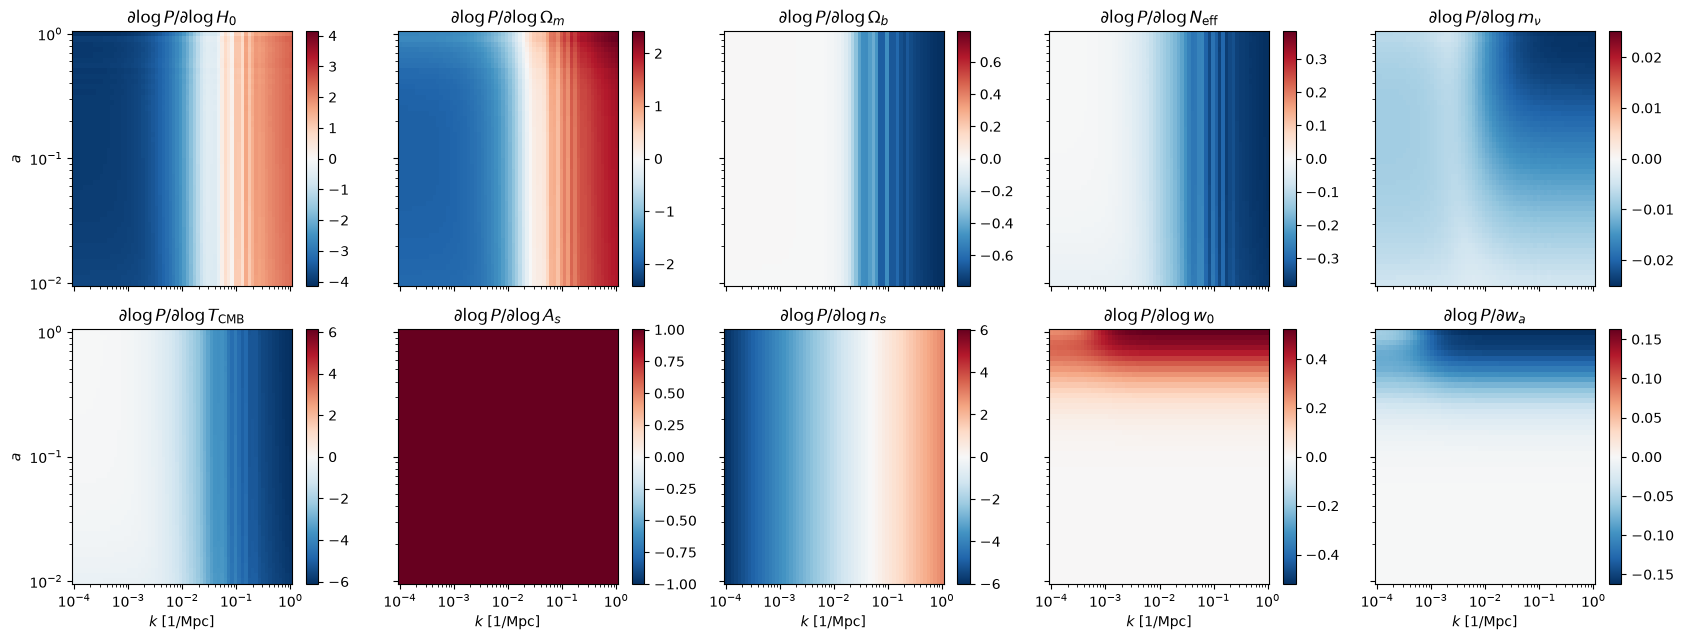

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True, sharey=True)
for i, (ax, label) in enumerate(zip(axes.flat, PARAMETERS.values())):
    limit = np.abs(response[..., i]).max()
    mesh = ax.pcolormesh(
        K, A_OUT, response[..., i].T, cmap="RdBu_r", vmin=-limit, vmax=limit
    )
    fig.colorbar(mesh, ax=ax)
    log = "" if theta[i] == 0.0 else r"\log "
    ax.set_title(rf"$\partial \log P / \partial {log}{label}$")
    ax.loglog()
for ax in axes[-1]:
    ax.set_xlabel(r"$k$ [1/Mpc]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$a$")
fig.tight_layout()
plt.show()